In [1]:
import pyro
import torch

import matplotlib.pyplot as plt

from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide, posterior_samples
from mmbo.examples.demo import paciorek_demo, branin_demo
from mmbo.training import do_svi

#device = "cuda:3"

## Get training data

In [2]:
X_train_main = branin_demo['X_train_main']
X_train_mm = branin_demo['X_train_mm']
X_test = branin_demo['X_test']
Y_train_main = branin_demo['Y_train_main']
Y_train_mm = branin_demo['Y_train_mm']
Y_test_main = branin_demo['Y_test_main']
Y_test_mm = branin_demo['Y_test_mm']

## Train uni-modal model

In [3]:
model = RegBNN.from_data(X_train = X_train_main, Y_train = Y_train_main, hidden_widths=[256,256])
guide = RegBNNGuide(model)

#model = model.to(device)
#guide = guide.to(device)

In [4]:
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

svi = pyro.infer.SVI(model, guide, adam, elbo)
params, losses = do_svi(svi, params = None)

2025-09-17 19:50:18 - Start


/home/itaylor/projects/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:275: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


2025-09-17 19:50:58 - Step 1000, Elbo loss: 47477.6 +/- 29363.2 (slope = -50378.730 +/- 429.344 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:51:30 - Step 2000, Elbo loss: 15875.5 +/- 10049.5 (slope = -17221.854 +/- 156.115 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:51:58 - Step 3000, Elbo loss: 5266.7 +/- 3303.9 (slope = -5658.519 +/- 52.794 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:52:26 - Step 4000, Elbo loss: 1771.6 +/- 1096.7 (slope = -1876.011 +/- 18.507 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:52:54 - Step 5000, Elbo loss: 611.7 +/- 363.8 (slope = -619.051 +/- 7.316 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:53:23 - Step 6000, Elbo loss: 230.6 +/- 122.2 (slope = -204.373 +/- 3.458 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:53:51 - Step 7000, Elbo loss: 103.4 +/- 45.4 (slope = -67.959 +/- 2.499 loss/k-iter, p-value = 0.000) + 
2025-09-17 19:54:20 - Step 8000, Elbo loss: 60.4 +/- 23.6 (slope = -23.926 +/- 2.093 loss/k-iter, p-value = 0.000) + 
2025-09-17 19

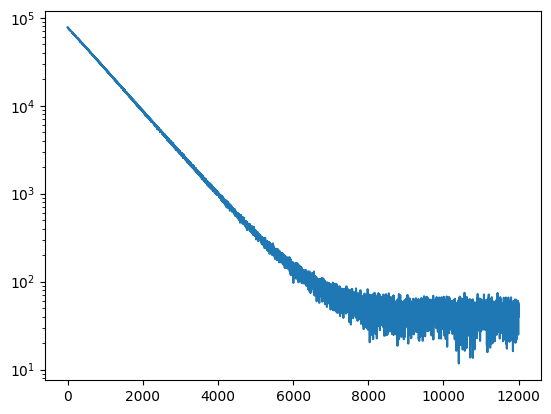

In [5]:
plt.plot(losses)
plt.yscale("log")

In [6]:
samples = posterior_samples(guide, params, 1000)

## Optimize expected improvement

In [7]:
from mmbo.optim import expected_improvement, lcb, probability_improvement, probability_improvement_sigmoid, expected_improvement_softplus

In [ ]:
n_swarm = 100

n_iter = 100

low_lim = torch.tensor([-5.0, 0.0])
high_lim = torch.tensor([10., 15.0])

# Paciorek
#X_init = torch.rand((n_swarm, 4)) * (high_lim - low_lim) + low_lim
# Branin
X_init = torch.rand((n_swarm, 2)) * (high_lim - low_lim) + low_lim

In [9]:


X_opt = X_init.clone()
X_opt.requires_grad_(True)

optim = torch.optim.Adam([X_opt], lr=0.05)

max_ei = [None]*n_iter
for iter in range(n_iter):
    optim.zero_grad()
    ei = expected_improvement_softplus(model, samples, X_opt, Y_train_main.min())
    gain = -ei
    max_ei[iter] = ei.max().detach().item()
    gain.sum().backward()
    optim.step()
    with torch.no_grad():
        X_opt.clamp_(min=low_lim, max=high_lim)
    print(f"{iter}: {max_ei[iter]}")


0: 29.79723358154297
1: 30.516277313232422
2: 31.213693618774414
3: 31.88474464416504
4: 32.52254867553711
5: 33.13731384277344
6: 33.725555419921875
7: 34.291969299316406
8: 34.83543014526367
9: 35.3618278503418
10: 35.871002197265625
11: 35.864768981933594
12: 35.857540130615234
13: 35.8510627746582
14: 35.845985412597656
15: 35.84235382080078
16: 35.840484619140625
17: 35.84029006958008
18: 35.84163284301758
19: 35.844303131103516
20: 35.847938537597656
21: 35.85227966308594
22: 35.8570442199707
23: 35.86183166503906
24: 35.86642837524414
25: 35.87281799316406
26: 35.87889862060547
27: 35.88247299194336
28: 35.88456344604492
29: 35.88542175292969
30: 35.88516616821289
31: 35.884342193603516
32: 35.884849548339844
33: 35.885337829589844
34: 35.885414123535156
35: 35.885074615478516
36: 35.88441467285156
37: 35.883670806884766
38: 35.88301467895508
39: 35.882389068603516
40: 35.88194274902344
41: 35.88167953491211
42: 35.881595611572266
43: 35.88169479370117
44: 35.88193130493164
45: 

(array([58., 11.,  8.,  0.,  0.,  0.,  0.,  0.,  1., 22.]),
 array([ 0.        ,  3.58854485,  7.17708969, 10.76563454, 14.35417938,
        17.94272423, 21.53126907, 25.11981392, 28.70835876, 32.29690552,
        35.88544846]),
 <BarContainer object of 10 artists>)

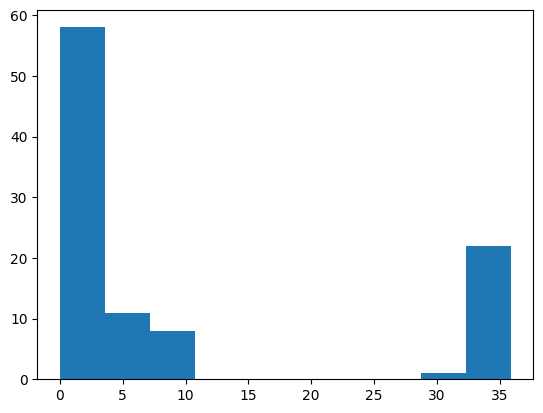

In [10]:
ei = expected_improvement_softplus(model, samples, X_opt, Y_train_main.min())
plt.hist(ei.detach())

tensor(5.4117) tensor(0.5067, grad_fn=<MinBackward1>)


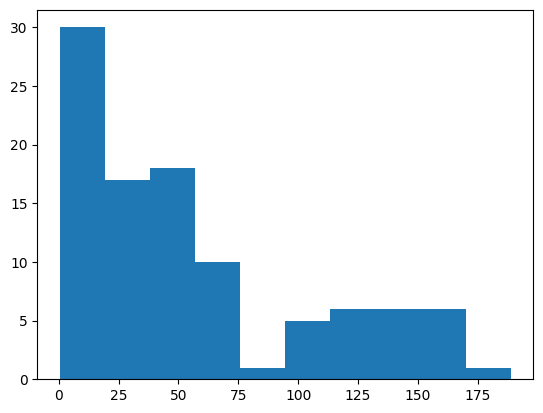

In [11]:
from mmbo.examples.testfunc import paciorek_hf, branin_hf

realized_values = branin_hf(X_opt)

plt.hist(realized_values.detach())

print(Y_train_main.min(), realized_values.min())

## Train multi-modal layered model

In [12]:
model_layered = LayeredRegBNN.from_data(X_train_main = X_train_main, Y_train_main = Y_train_main, X_train_aux = X_train_mm, Y_train_aux = Y_train_mm, hidden_widths=[256,256])
guide_layered = LayeredRegBNNGuide(model_layered)

In [13]:
adam_layered = pyro.optim.Adam({"lr": 0.001})
elbo_layered = pyro.infer.Trace_ELBO(num_particles = 1)

svi_layered = pyro.infer.SVI(model_layered, guide_layered, adam_layered, elbo_layered)
params_layered, losses_layered = do_svi(svi_layered, params = None)

2025-09-17 20:03:46 - Start
2025-09-17 20:04:36 - Step 1000, Elbo loss: 47668.9 +/- 29331.0 (slope = -50327.682 +/- 426.936 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:05:27 - Step 2000, Elbo loss: 16040.9 +/- 10084.5 (slope = -17283.393 +/- 156.011 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:06:17 - Step 3000, Elbo loss: 5355.2 +/- 3341.5 (slope = -5721.577 +/- 53.982 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:07:06 - Step 4000, Elbo loss: 1820.1 +/- 1106.7 (slope = -1893.466 +/- 18.533 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:07:55 - Step 5000, Elbo loss: 639.5 +/- 382.7 (slope = -650.393 +/- 7.999 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:08:44 - Step 6000, Elbo loss: 232.7 +/- 140.0 (slope = -231.190 +/- 4.611 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:09:32 - Step 7000, Elbo loss: 82.1 +/- 62.6 (slope = -91.165 +/- 3.709 loss/k-iter, p-value = 0.000) + 
2025-09-17 20:10:24 - Step 8000, Elbo loss: 21.2 +/- 39.1 (slope = -36.842 +/- 3.601 loss/k-iter, p-valu

In [14]:
samples_layered = posterior_samples(guide_layered, params_layered, 1000)

In [15]:
X_opt_layered = X_init.clone()
X_opt_layered.requires_grad_(True)

optim_layered = torch.optim.Adam([X_opt_layered], lr=0.05)

max_ei_layered = [None]*n_iter
for iter in range(n_iter):
    optim_layered.zero_grad()
    ei = expected_improvement_softplus(model_layered, samples_layered, X_opt_layered, Y_train_main.min())
    gain = -ei
    max_ei_layered[iter] = ei.max().detach().item()
    gain.sum().backward()
    optim_layered.step()
    with torch.no_grad():
        X_opt_layered.clamp_(min=low_lim, max=high_lim)
    print(f"{iter}: {max_ei_layered[iter]}")

0: 4.174596309661865
1: 4.203138828277588
2: 4.216141223907471
3: 4.2246222496032715
4: 4.2549238204956055
5: 4.2761454582214355
6: 4.285002708435059
7: 4.2845778465271
8: 4.28589391708374
9: 4.3013434410095215
10: 4.359720230102539
11: 4.822939395904541
12: 5.277743339538574
13: 5.727656841278076
14: 6.166409015655518
15: 6.594223976135254
16: 7.012330055236816
17: 7.41709041595459
18: 7.80573844909668
19: 8.178201675415039
20: 8.534394264221191
21: 8.872817039489746
22: 9.196964263916016
23: 9.42308235168457
24: 9.475492477416992
25: 9.526253700256348
26: 9.575167655944824
27: 9.620992660522461
28: 9.663844108581543
29: 9.846000671386719
30: 10.07104778289795
31: 10.290980339050293
32: 10.369006156921387
33: 10.368972778320312
34: 10.368961334228516
35: 10.368965148925781
36: 10.368987083435059
37: 10.369024276733398
38: 10.369085311889648
39: 10.369175910949707
40: 10.369283676147461
41: 10.375101089477539
42: 10.374879837036133
43: 10.374394416809082
44: 10.374005317687988
45: 10.3

(array([51.,  0.,  1., 24., 13.,  0.,  0.,  0.,  0., 11.]),
 array([ 0.        ,  1.0375129 ,  2.0750258 ,  3.11253881,  4.15005159,
         5.18756437,  6.22507763,  7.26259041,  8.30010319,  9.33761597,
        10.37512875]),
 <BarContainer object of 10 artists>)

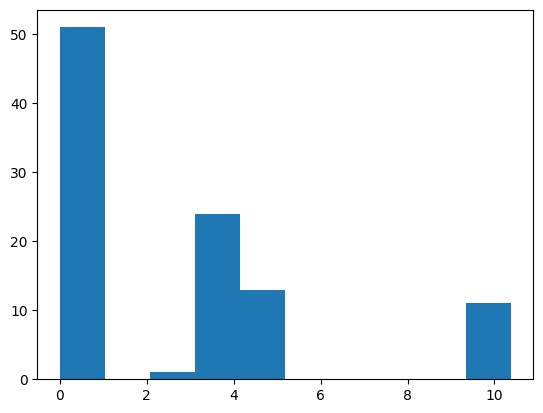

In [16]:
ei = expected_improvement_softplus(model_layered, samples_layered, X_opt_layered, Y_train_main.min())
plt.hist(ei.detach())

tensor(5.4117) tensor(0.4040, grad_fn=<MinBackward1>)


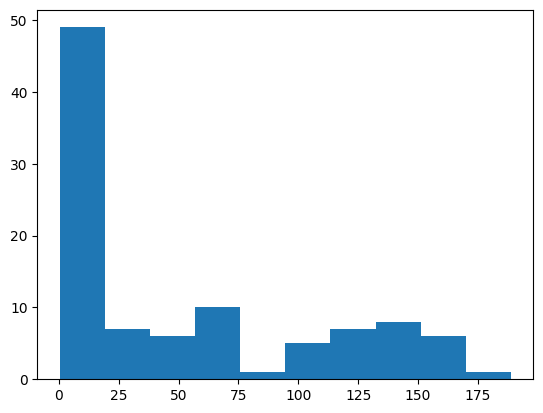

In [17]:
realized_values = branin_hf(X_opt_layered)

plt.hist(realized_values.detach())

print(Y_train_main.min(), realized_values.min())

## Plot explored points for each model

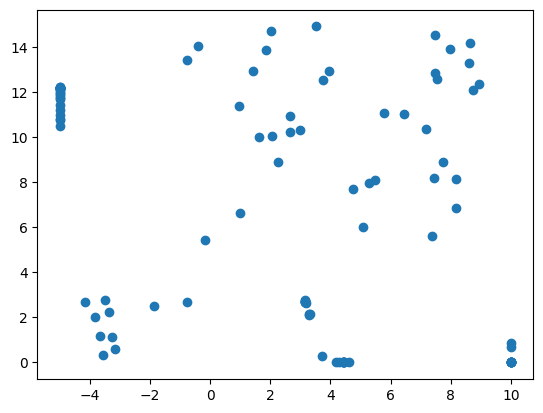

In [18]:
plt.scatter(X_opt[:,0].detach(), X_opt[:,1].detach())

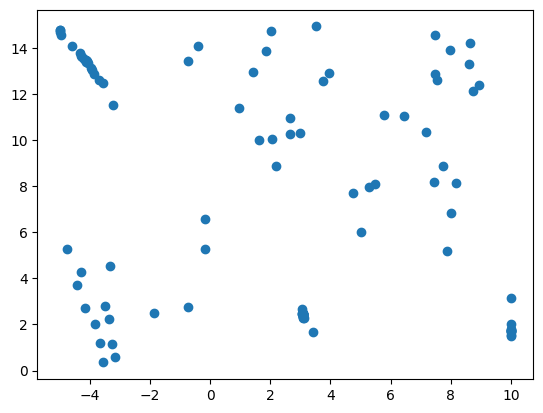

In [19]:
plt.scatter(X_opt_layered[:,0].detach(), X_opt_layered[:,1].detach())

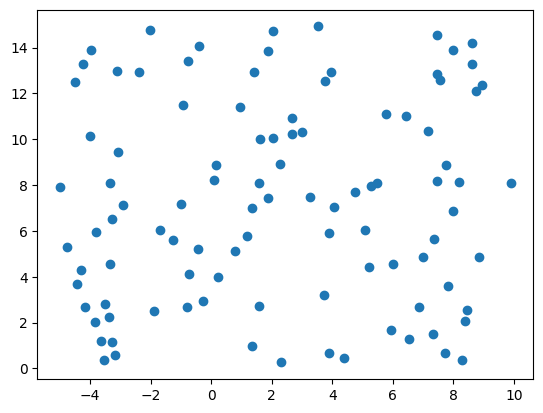

In [20]:
plt.scatter(X_init[:,0], X_init[:,1])

## Use botorch optimizer on fitted models

In [58]:
import botorch

objective = lambda x: probability_improvement_sigmoid(model, samples, x, Y_train_main.min())

num_raw = 1000
num_points = 50

raw_candidates = torch.rand((num_raw, 2)) * (high_lim - low_lim) + low_lim
raw_objective = objective(raw_candidates)
_,bestidx = torch.topk(raw_objective.squeeze(), num_points)
candidates = raw_candidates[bestidx]

#botorch.optim.optimize_acqf(objective, bounds, num_candidates, num_restarts, raw_samples = raw_samples)

#

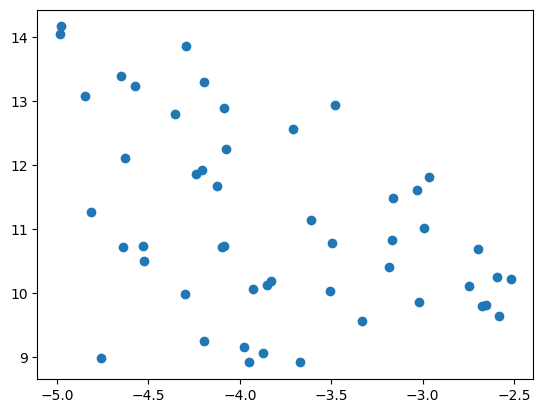

In [ ]:
plt.scatter(candidates[:,0], candidates[:,1])
plt.xlim()

In [60]:
X_final,ei_final = botorch.gen_candidates_scipy(candidates, objective, low_lim, high_lim)

tensor([[0.9932],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9930],
        [0.9932],
        [0.9931],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9930],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9930],
        [0.9930],
        [0.9930],
        [0.9932],
        [0.9930],
        [0.9932],
        [0.9932],
        [0.9932],
        [0.9931],
        [0.9930]])

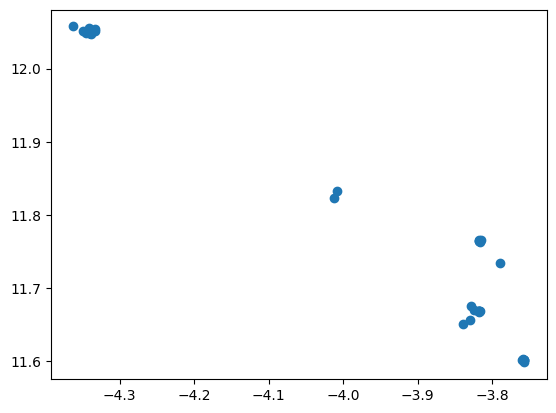

In [61]:
plt.scatter(X_final[:,0], X_final[:,1])
ei_final